# Assignment 2: Embeddings and Hidden Markov Models

**Dataset:** CoNLL-2000 (`eriktks/conll2000`) — only the `tokens` and `pos_tags` fields are used.

**Notebook outline**
0. Setup, data loading, train/validation split, preprocessing & vocabulary
1. Sparse and dense word representations (PMI, TF-IDF, Word2Vec)
2. HMM POS tagger with Viterbi decoding
3. Embedding-assisted HMM

## 0. Setup

All randomness goes through one seeded generator so every run produces the same split.

In [1]:
import re
from collections import Counter

import numpy as np
from datasets import load_dataset

SEED = 42
VALIDATION_FRACTION = 0.10   # share of the official train partition held out for tuning
MIN_COUNT = 2                # words seen fewer times in training are mapped to <UNK>

UNK_TOKEN = "<UNK>"
NUM_TOKEN = "<NUM>"

rng = np.random.default_rng(SEED)

C:\Users\kero samy\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0.1 Load the raw data

The dataset repository ships a loading script, which recent versions of `datasets` no longer execute,
so we load Hugging Face's auto-converted Parquet files (`refs/convert/parquet`) — the same data.

POS tags are stored as integer class ids; we decode them to tag strings and discard `chunk_tags`.

In [2]:
def decode_tags(tag_ids, tag_names):
    """Convert a list of integer tag ids into tag strings (e.g. 19 -> 'NN')."""
    tags = []
    for tag_id in tag_ids:
        tags.append(tag_names[tag_id])
    return tags


def load_conll2000():
    """Load CoNLL-2000 and return {'train': sentences, 'test': sentences}.

    Each sentence is a pair (tokens, tags). Chunk tags are not used.
    """
    raw = load_dataset("eriktks/conll2000", revision="refs/convert/parquet")
    tag_names = raw["train"].features["pos_tags"].feature.names

    data = {}
    for split_name in ["train", "test"]:
        sentences = []
        for row in raw[split_name]:
            tokens = row["tokens"]
            tags = decode_tags(row["pos_tags"], tag_names)
            sentences.append((tokens, tags))
        data[split_name] = sentences
    return data


data = load_conll2000()
print("train sentences:", len(data["train"]))
print("test sentences: ", len(data["test"]))

first_tokens, first_tags = data["train"][0]
print("\nFirst training sentence (first 8 words):")
for i in range(8):
    print(f"  {first_tokens[i]:<12} {first_tags[i]}")

train sentences: 8937
test sentences:  2013

First training sentence (first 8 words):
  Confidence   NN
  in           IN
  the          DT
  pound        NN
  is           VBZ
  widely       RB
  expected     VBN
  to           TO


## 0.2 Train / validation split

The official **test** partition is kept untouched for final evaluation only.
We shuffle the official **train** partition with a fixed seed and hold out 10% as a validation set,
which is used for all hyperparameter tuning.

In [3]:
def train_validation_split(sentences, validation_fraction, rng):
    """Shuffle the sentences with a seeded generator and split them into (train, validation)."""
    shuffled_indices = rng.permutation(len(sentences))
    n_validation = round(len(sentences) * validation_fraction)

    validation_sentences = []
    train_sentences = []
    for position, index in enumerate(shuffled_indices):
        if position < n_validation:
            validation_sentences.append(sentences[index])
        else:
            train_sentences.append(sentences[index])
    return train_sentences, validation_sentences


def count_tokens(sentences):
    """Total number of tokens in a list of (tokens, tags) pairs."""
    total = 0
    for tokens, tags in sentences:
        total += len(tokens)
    return total


train_sents, val_sents = train_validation_split(data["train"], VALIDATION_FRACTION, rng)
test_sents = data["test"]

splits = {
    "train": train_sents,
    "validation": val_sents,
    "test": test_sents,
}

for split_name in splits:
    sentences = splits[split_name]
    print(f"{split_name:<11} {len(sentences):>5} sentences  {count_tokens(sentences):>6} tokens")

train        8043 sentences  190358 tokens
validation    894 sentences   21369 tokens
test         2013 sentences   47377 tokens


## 0.3 Preprocessing

We keep **two views** of the same sentences, because the two halves of the assignment need different things:

| View | Used by | Processing | Why |
|---|---|---|---|
| **HMM view** | Parts 2 & 3 (tagging) | Original tokens and tags, unchanged | Capitalisation (`NNP`), digits (`CD`) and punctuation (`,` `.` `:`) are strong POS cues and all carry gold tags. |
| **Embedding view** | Part 1 (PMI, TF-IDF, Word2Vec) | Lowercase, numbers → `<NUM>`, punctuation-only tokens removed | Merges `The`/`the` and thousands of distinct numbers into shared types, shrinking the vocabulary and reducing sparsity; punctuation co-occurs with everything and would only add noise to context windows. |

Rules for the embedding view:
* **Lowercasing** — sentence-initial capitalisation otherwise splits one word into two types.
* **Number normalisation** — any token made only of digits and numeric punctuation (`3.5`, `1,000`, `1\/2`, `20%`) becomes `<NUM>`.
  Individual numbers are rare and semantically interchangeable.
* **Punctuation removal** — tokens with no letter or digit (`,` `.` `--` `` ` `` `$`) are dropped.
  Clitics like `'s` and `n't` contain letters and are kept, as they are meaningful words.

In [4]:
# A number: only digits and numeric punctuation, with at least one digit (3.5, 1,000, 1\/2, 20%).
NUMBER_PATTERN = re.compile(r"[\d.,:/\\%+-]*\d[\d.,:/\\%+-]*")
# Used to detect punctuation-only tokens (tokens with no letter or digit).
ALPHANUMERIC_PATTERN = re.compile(r"[A-Za-z0-9]")


def normalize_token(token):
    """Return the embedding-view form of a token, or None if the token should be dropped."""
    if NUMBER_PATTERN.fullmatch(token):
        return NUM_TOKEN

    is_punctuation = ALPHANUMERIC_PATTERN.search(token) is None
    if is_punctuation:
        return None

    return token.lower()


def to_embedding_view(sentences):
    """Convert (tokens, tags) pairs into lists of normalized tokens. Tags are not needed here."""
    corpus = []
    for tokens, tags in sentences:
        normalized_sentence = []
        for token in tokens:
            normalized = normalize_token(token)
            if normalized is not None:
                normalized_sentence.append(normalized)
        corpus.append(normalized_sentence)
    return corpus


embedding_corpus = {}
for split_name in splits:
    embedding_corpus[split_name] = to_embedding_view(splits[split_name])

example_tokens, example_tags = train_sents[0]
print("raw       :", " ".join(example_tokens))
print("embedding :", " ".join(embedding_corpus["train"][0]))

raw       : Which types of stocks are most likely to qualify ?
embedding : which types of stocks are most likely to qualify


## 0.4 Vocabulary

The vocabulary is built **from the training split only**, so validation/test words are genuinely unseen when they are not in it.
Words seen fewer than `MIN_COUNT` times are mapped to `<UNK>`: a word seen once gives a single, very noisy context
and inflates every matrix in Part 1. `MIN_COUNT` is a hyperparameter and is revisited during validation tuning.

Ids are assigned by descending frequency (ties broken alphabetically), so the order is deterministic.

In [5]:
def count_words(corpus):
    """Count how many times each word appears in a list of tokenized sentences."""
    word_counts = Counter()
    for sentence in corpus:
        for word in sentence:
            word_counts[word] += 1
    return word_counts


class Vocabulary:
    """Maps words to integer ids and back. Id 0 is reserved for <UNK>."""

    def __init__(self, corpus, min_count):
        word_counts = count_words(corpus)

        # Keep only words that appear at least min_count times.
        kept_words = []
        for word in word_counts:
            if word_counts[word] >= min_count:
                kept_words.append(word)

        # Order by frequency (most frequent first); ties are broken alphabetically.
        # Python's sort is stable, so sorting alphabetically first and then by count keeps that order.
        kept_words.sort()
        kept_words.sort(key=word_counts.get, reverse=True)

        self.id_to_word = [UNK_TOKEN] + kept_words
        self.word_to_id = {}
        for word_id, word in enumerate(self.id_to_word):
            self.word_to_id[word] = word_id
        self.unk_id = self.word_to_id[UNK_TOKEN]

        # Frequency of every vocabulary entry; rare words add to the <UNK> count.
        self.counts = np.zeros(len(self.id_to_word), dtype=np.int64)
        for word in word_counts:
            self.counts[self.get_id(word)] += word_counts[word]

    def __len__(self):
        return len(self.id_to_word)

    def __contains__(self, word):
        return word in self.word_to_id

    def get_id(self, word):
        """Id of a word, or the <UNK> id if the word is not in the vocabulary."""
        if word in self.word_to_id:
            return self.word_to_id[word]
        return self.unk_id

    def encode(self, sentence):
        """Convert a list of words into a list of ids."""
        ids = []
        for word in sentence:
            ids.append(self.get_id(word))
        return ids

    def decode(self, ids):
        """Convert a list of ids back into words."""
        words = []
        for word_id in ids:
            words.append(self.id_to_word[word_id])
        return words


vocab = Vocabulary(embedding_corpus["train"], MIN_COUNT)

encoded_corpus = {}
for split_name in embedding_corpus:
    encoded_sentences = []
    for sentence in embedding_corpus[split_name]:
        encoded_sentences.append(vocab.encode(sentence))
    encoded_corpus[split_name] = encoded_sentences

print(f"vocabulary size (including {UNK_TOKEN}): {len(vocab)}")
print("15 most frequent words:", vocab.id_to_word[1:16])

vocabulary size (including <UNK>): 7886
15 most frequent words: ['the', '<NUM>', 'of', 'to', 'a', 'in', 'and', 'for', "'s", 'that', 'is', 'said', 'it', 'on', 'at']


### Vocabulary coverage

How many running tokens fall outside the vocabulary in each split (embedding view).

In [6]:
def unk_rate(encoded_sentences, unk_id):
    """Fraction of tokens that were mapped to <UNK>."""
    n_unknown = 0
    n_total = 0
    for sentence in encoded_sentences:
        for word_id in sentence:
            n_total += 1
            if word_id == unk_id:
                n_unknown += 1
    return n_unknown / n_total


n_train_types = len(count_words(embedding_corpus["train"]))
print(f"distinct training words: {n_train_types}")
print(f"kept in vocabulary (count >= {MIN_COUNT}): {len(vocab) - 1}")
print()

for split_name in encoded_corpus:
    rate = unk_rate(encoded_corpus[split_name], vocab.unk_id)
    print(f"{split_name:<11} <UNK> rate: {rate:6.2%}")

distinct training words: 14688
kept in vocabulary (count >= 2): 7885

train       <UNK> rate:  4.10%
validation  <UNK> rate:  6.73%
test        <UNK> rate:  9.61%


### Unknown words for the HMM

For tagging, a word is *unknown* when its exact surface form never appears in the training split.
We record this now so that Parts 2 and 3 can report unknown-word results separately.

In [7]:
def collect_words_and_tags(sentences):
    """Return the set of distinct words and the set of distinct tags in (tokens, tags) pairs."""
    words = set()
    tags = set()
    for sentence_tokens, sentence_tags in sentences:
        for token in sentence_tokens:
            words.add(token)
        for tag in sentence_tags:
            tags.add(tag)
    return words, tags


def count_unknown_tokens(sentences, known_words):
    """Return (number of tokens not in known_words, total number of tokens)."""
    n_unknown = 0
    n_total = 0
    for tokens, tags in sentences:
        for token in tokens:
            n_total += 1
            if token not in known_words:
                n_unknown += 1
    return n_unknown, n_total


hmm_train_words, train_tag_set = collect_words_and_tags(train_sents)
all_tags = sorted(train_tag_set)

print(f"HMM training word types: {len(hmm_train_words)}")
print(f"POS tags: {len(all_tags)}")
print()

for split_name in ["validation", "test"]:
    n_unknown, n_total = count_unknown_tokens(splits[split_name], hmm_train_words)
    print(f"{split_name:<11} unknown tokens: {n_unknown:>5} / {n_total} ({n_unknown / n_total:.2%})")

HMM training word types: 18124
POS tags: 44

validation  unknown tokens:  1037 / 21369 (4.85%)
test        unknown tokens:  3438 / 47377 (7.26%)


### Summary of objects produced in this section

| Name | Contents |
|---|---|
| `train_sents`, `val_sents`, `test_sents` | HMM view: lists of `(tokens, tags)` |
| `embedding_corpus[split]` | Embedding view: lists of normalised tokens |
| `vocab` | `Vocabulary` built from the training embedding view |
| `encoded_corpus[split]` | Embedding view as lists of vocabulary ids |
| `hmm_train_words` | Surface forms seen in training (defines HMM unknown words) |

# Part 1: Sparse and Dense Word Representations

All three representations are built from the **training split only**, on the embedding view
(`encoded_corpus["train"]`), and share the same `vocab`, so row `i` always means the same word.

| Representation | Rows | Columns | Kind |
|---|---|---|---|
| PPMI | words | context words (±window) | sparse |
| TF-IDF | words | training sentences (documents) | sparse |
| Word2Vec (SGNS) | words | learned dimensions | dense |

**Hyperparameters and tuning.** Word2Vec is tuned below on its validation loss.
PMI and TF-IDF have no training objective to validate against, so their settings
(`PMI_WINDOW`, `MIN_COUNT`, TF scaling) are chosen in Part 3 by the validation tagging accuracy
of the embedding-assisted HMM. The values below are the starting defaults.

In [8]:
import time

import matplotlib.pyplot as plt

# --- PMI (lecture 03: PMI = log2 P(w,c) / (P(w) P(c)), PPMI = max(PMI, 0)) ---
PMI_WINDOW = 2              # neighbours counted on each side of a word
CONTEXT_SMOOTHING = 0.75    # alpha for P_alpha(c); alpha = 1 is the plain lecture formula

# --- TF-IDF (lecture 03: tf = 1 + log10 f, idf = log10 N / df) ---
SUBLINEAR_TF = True         # use 1 + log10(tf) instead of the raw count tf

# --- Word2Vec (Skip-Gram with Negative Sampling, lecture 04) ---
W2V_DIM = 50                # embedding size: tuned on validation below
W2V_LEARNING_RATE = 0.025   # starting SGD step size (decays linearly to ~0): tuned on validation below
W2V_EPOCHS = 10             # maximum; the epoch with the lowest validation loss is kept
W2V_WINDOW = 2              # context words on each side of the center word
W2V_NEGATIVES = 5           # K: negative samples per (center, context) pair
W2V_BATCH_SIZE = 256
SUBSAMPLE_THRESHOLD = 1e-3  # frequent words are randomly dropped (word2vec "sample" parameter)
NEGATIVE_POWER = 0.75       # negatives drawn from P_alpha(w) = count(w)^0.75 / sum count^0.75

N_NEIGHBOURS = 8            # neighbours shown per query word

## 1.1 A sparse matrix class

Most word pairs never co-occur, so a full `V × V` matrix (7,886 × 7,886 ≈ 62 M cells) would be almost all zeros.
We store only the non-zero entries in **compressed sparse row (CSR)** format, implemented with three NumPy arrays:

* `data` — the non-zero values, row after row
* `indices` — the column of each value
* `indptr` — row `r` owns the entries `indptr[r]` up to (not including) `indptr[r + 1]`

Example: the matrix `[[0, 5, 0], [0, 0, 0], [2, 0, 7]]` is stored as
`data = [5, 2, 7]`, `indices = [1, 0, 2]`, `indptr = [0, 1, 1, 3]` (row 1 is empty: it owns entries 1 to 1).

In [9]:
class SparseRowMatrix:
    """A compressed sparse row (CSR) matrix that stores only its non-zero entries."""

    def __init__(self, rows, cols, values, shape):
        """Build the matrix from parallel arrays: entry k is values[k] at (rows[k], cols[k])."""
        # Sort entries by row (then column) so that each row's entries sit next to each other.
        order = np.lexsort((cols, rows))
        self.shape = shape
        self.indices = cols[order].astype(np.int32)
        self.data = values[order].astype(np.float32)

        entries_per_row = np.bincount(rows, minlength=shape[0])
        self.indptr = np.zeros(shape[0] + 1, dtype=np.int64)
        self.indptr[1:] = np.cumsum(entries_per_row)

    def nnz(self):
        """Number of stored (non-zero) entries."""
        return len(self.data)

    def row_ids(self):
        """Row index of every stored entry, in storage order."""
        entries_per_row = np.diff(self.indptr)
        return np.repeat(np.arange(self.shape[0]), entries_per_row)

    def row_entries(self, row):
        """Return (column indices, values) of the non-zero entries in one row."""
        start = self.indptr[row]
        end = self.indptr[row + 1]
        return self.indices[start:end], self.data[start:end]

    def dense_row(self, row):
        """Return one row as a full NumPy vector (zeros included)."""
        vector = np.zeros(self.shape[1], dtype=np.float32)
        columns, values = self.row_entries(row)
        vector[columns] = values
        return vector

    def dot_rows_with(self, vector):
        """Dot product of every row with a dense vector; returns one number per row."""
        products = self.data * vector[self.indices]
        return np.bincount(self.row_ids(), weights=products, minlength=self.shape[0])

    def row_norms(self):
        """Euclidean length of every row."""
        squares = self.data.astype(np.float64) ** 2
        return np.sqrt(np.bincount(self.row_ids(), weights=squares, minlength=self.shape[0]))

    def storage_bytes(self):
        """Memory used by the three CSR arrays."""
        return self.data.nbytes + self.indices.nbytes + self.indptr.nbytes


# Check the class on the small example from the text above.
example = SparseRowMatrix(
    rows=np.array([0, 2, 2]),
    cols=np.array([1, 0, 2]),
    values=np.array([5.0, 2.0, 7.0]),
    shape=(3, 3),
)
print("data   :", example.data)
print("indices:", example.indices)
print("indptr :", example.indptr)
print("row 2  :", example.dense_row(2))

data   : [5. 2. 7.]
indices: [1 0 2]
indptr : [0 1 1 3]
row 2  : [2. 0. 7.]


## 1.2 Similarity search (shared by all three representations)

Words are compared with **cosine similarity**, the cosine of the angle between two vectors:

$$\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

It ignores vector length, which mostly reflects word frequency, and compares only the direction (the pattern of contexts).
`<UNK>` and the query word itself are never returned as neighbours.

In [10]:
def cosine_from_dot_products(dot_products, norms, query_id):
    """Turn the dot products (query · every word) into cosine similarities."""
    denominators = norms * norms[query_id]
    similarities = np.zeros(len(dot_products))
    has_length = denominators > 0          # rows of all zeros have no direction
    similarities[has_length] = dot_products[has_length] / denominators[has_length]
    return similarities


def sparse_cosine_similarities(matrix, query_id):
    """Cosine similarity between one row of a SparseRowMatrix and every row."""
    query_vector = matrix.dense_row(query_id)
    dot_products = matrix.dot_rows_with(query_vector)
    return cosine_from_dot_products(dot_products, matrix.row_norms(), query_id)


def dense_cosine_similarities(embeddings, query_id):
    """Cosine similarity between one row of a dense matrix and every row."""
    dot_products = embeddings @ embeddings[query_id]
    norms = np.linalg.norm(embeddings, axis=1)
    return cosine_from_dot_products(dot_products, norms, query_id)


def nearest_neighbours(similarities, query_id, vocab, k):
    """Return the k most similar words as (word, similarity) pairs, skipping the query and <UNK>."""
    ranked_ids = np.argsort(-similarities)
    neighbours = []
    for word_id in ranked_ids:
        if word_id == query_id or word_id == vocab.unk_id:
            continue
        neighbours.append((vocab.id_to_word[word_id], similarities[word_id]))
        if len(neighbours) == k:
            break
    return neighbours


def format_neighbours(neighbours):
    """Format (word, similarity) pairs as 'word (0.42), word (0.37), ...'."""
    parts = []
    for word, similarity in neighbours:
        parts.append(f"{word} ({similarity:.2f})")
    return ", ".join(parts)

## 1.3 PMI

### Word–context co-occurrence counts

For every word in a training sentence, each word up to `PMI_WINDOW` positions to its left or right is one of its contexts.
Counting is symmetric: if *a* is a context of *b*, then *b* is a context of *a*.

In [11]:
def count_cooccurrences(encoded_sentences, window):
    """Count (word, context) pairs that appear within `window` positions of each other."""
    pair_counts = Counter()
    for sentence in encoded_sentences:
        for position in range(len(sentence)):
            word = sentence[position]
            for offset in range(1, window + 1):
                if position + offset >= len(sentence):
                    break
                context = sentence[position + offset]
                pair_counts[(word, context)] += 1
                pair_counts[(context, word)] += 1
    return pair_counts


def pair_counts_to_sparse(pair_counts, size):
    """Convert a {(row, col): count} Counter into a size × size SparseRowMatrix."""
    n_pairs = len(pair_counts)
    rows = np.zeros(n_pairs, dtype=np.int64)
    cols = np.zeros(n_pairs, dtype=np.int64)
    values = np.zeros(n_pairs, dtype=np.float64)

    position = 0
    for (row, col), count in pair_counts.items():
        rows[position] = row
        cols[position] = col
        values[position] = count
        position += 1
    return SparseRowMatrix(rows, cols, values, (size, size))


pair_counts = count_cooccurrences(encoded_corpus["train"], PMI_WINDOW)
count_matrix = pair_counts_to_sparse(pair_counts, len(vocab))

n_cells = len(vocab) * len(vocab)
print(f"co-occurrence matrix: {count_matrix.shape}, non-zero cells: {count_matrix.nnz()} "
      f"({count_matrix.nnz() / n_cells:.2%} of all cells)")

co-occurrence matrix: (7886, 7886), non-zero cells: 275709 (0.44% of all cells)


### From counts to PPMI

Following lecture 03, with $f_{ij}$ the count of word $i$ with context $j$ and $N = \sum_i \sum_j f_{ij}$:

$$P(w, c) = \frac{f_{wc}}{N}, \qquad P(w) = \frac{\text{row sum}}{N}, \qquad P(c) = \frac{\text{column sum}}{N}$$

$$\mathrm{PMI}(w, c) = \log_2 \frac{P(w, c)}{P(w)\,P(c)}, \qquad \mathrm{PPMI}(w, c) = \max\big(\mathrm{PMI}(w, c),\ 0\big)$$

* **Why positive PMI.** Negative values ("occur together *less* than chance") are unreliable unless the corpus is enormous,
  and pairs never seen together have $\mathrm{PMI} = \log_2 0 = -\infty$. Replacing negatives by 0 removes both problems
  and keeps the matrix sparse.
* **Context smoothing (variant).** PMI over-rates rare contexts: a tiny $P(c)$ makes the fraction huge.
  The recommended reading (Jurafsky & Martin, §6.6) fixes this by raising context counts to a power $\alpha < 1$:
  $P_\alpha(c) = \frac{\#(c)^\alpha}{\sum_{c'} \#(c')^\alpha}$. With $\alpha = 1$ this is exactly the lecture formula.
  We build **both**: `plain_ppmi_matrix` ($\alpha = 1$, lecture) and `ppmi_matrix` ($\alpha = 0.75$), and compare them below.

In [12]:
def ppmi_from_counts(count_matrix, alpha):
    """PPMI = max(log2 P(w,c) / (P(w) P_alpha(c)), 0), computed only on the non-zero counts.

    alpha = 1 gives the plain lecture formula. Returns (PPMI matrix, number of negative PMI values).
    """
    rows = count_matrix.row_ids()
    cols = count_matrix.indices
    counts = count_matrix.data.astype(np.float64)
    size = count_matrix.shape[0]

    total = counts.sum()                                              # N
    word_totals = np.bincount(rows, weights=counts, minlength=size)   # row sums
    context_totals = np.bincount(cols, weights=counts, minlength=size)  # column sums
    smoothed_context_totals = context_totals ** alpha

    p_word_context = counts / total
    p_word = word_totals[rows] / total
    p_context = smoothed_context_totals[cols] / smoothed_context_totals.sum()
    pmi = np.log2(p_word_context / (p_word * p_context))

    is_positive = pmi > 0
    n_negative = np.sum(pmi < 0)
    ppmi = SparseRowMatrix(rows[is_positive], cols[is_positive], pmi[is_positive], count_matrix.shape)
    return ppmi, n_negative


plain_ppmi_matrix, n_negative_plain = ppmi_from_counts(count_matrix, alpha=1.0)
ppmi_matrix, n_negative_smoothed = ppmi_from_counts(count_matrix, alpha=CONTEXT_SMOOTHING)

print(f"observed pairs: {count_matrix.nnz()}")
print(f"plain PPMI    (alpha = 1)   : {n_negative_plain} negative PMI values set to 0, "
      f"{plain_ppmi_matrix.nnz()} non-zero cells left")
print(f"smoothed PPMI (alpha = {CONTEXT_SMOOTHING}): {n_negative_smoothed} negative PMI values set to 0, "
      f"{ppmi_matrix.nnz()} non-zero cells left")

observed pairs: 275709
plain PPMI    (alpha = 1)   : 23335 negative PMI values set to 0, 252374 non-zero cells left
smoothed PPMI (alpha = 0.75): 21410 negative PMI values set to 0, 254299 non-zero cells left


### How PPMI differs from raw counts

For the same word we list its strongest contexts and its nearest neighbours under raw counts, plain PPMI (lecture, $\alpha = 1$)
and smoothed PPMI ($\alpha = 0.75$).

In [13]:
def strongest_entries(matrix, row, vocab, k):
    """The k largest entries in one row, as (column word, value) pairs."""
    columns, values = matrix.row_entries(row)
    order = np.argsort(-values)
    result = []
    for position in order[:k]:
        result.append((vocab.id_to_word[columns[position]], values[position]))
    return result


weightings = {
    "raw counts": count_matrix,
    "plain PPMI": plain_ppmi_matrix,
    "smoothed PPMI": ppmi_matrix,
}

for word in ["stock", "rose"]:
    word_id = vocab.get_id(word)
    print(f"=== {word} ===")
    for name in weightings:
        contexts = strongest_entries(weightings[name], word_id, vocab, 7)
        print(f"top contexts, {name:<14}: {format_neighbours(contexts)}")
    for name in weightings:
        similarities = sparse_cosine_similarities(weightings[name], word_id)
        neighbours = nearest_neighbours(similarities, word_id, vocab, 6)
        print(f"neighbours,   {name:<14}: {format_neighbours(neighbours)}")
    print()

=== stock ===
top contexts, raw counts    : the (98.00), exchange (69.00), new (51.00), york (50.00), market (48.00), in (34.00), of (28.00)
top contexts, plain PPMI    : top-tier (7.19), collateral (7.19), preferred (6.76), grossly (6.38), indexed (6.19), boy (6.19), quotes (6.19)
top contexts, smoothed PPMI : exchange (6.28), preferred (6.07), composite (5.95), top-tier (5.81), collateral (5.81), york (5.63), grossly (4.96)
neighbours,   raw counts    : mercantile (0.70), new (0.69), state (0.69), u.s. (0.69), government (0.68), company (0.68)
neighbours,   plain PPMI    : exchange (0.23), preferred (0.17), shares (0.14), convertible (0.13), market (0.12), prices (0.11)
neighbours,   smoothed PPMI : exchange (0.25), preferred (0.18), shares (0.17), market (0.14), convertible (0.13), trading (0.13)

=== rose ===
top contexts, raw counts    : <NUM> (179.00), to (103.00), net (22.00), revenue (21.00), sales (20.00), in (15.00), <UNK> (14.00)
top contexts, plain PPMI    : snet (7.12), fl

**Observations**

* **Raw counts are dominated by frequent words.** The strongest contexts of *stock* are *the*, *exchange*, *new*, *york*,
  and of *rose* they are `<NUM>` and *to*. Every noun appears next to *the*, so with raw counts *stock* looks about equally similar (≈ 0.7)
  to any frequent noun: *state*, *government*, *company*. The scores are high but don't separate meanings.
* **PPMI asks whether a context is more frequent than chance.** *the* disappears from the top contexts. The neighbours of *stock* become
  *exchange*, *preferred*, *shares*, *market*, *convertible*, and the neighbours of *rose* become *fell*, *edged*, *jumped*, *climbed*.
  The scores are lower but separate words much better.
* **Plain PPMI (lecture formula, $\alpha = 1$) shows PMI's rare-word bias very clearly.** The strongest contexts of *stock* are
  *top-tier*, *collateral*, *grossly* and of *rose* are *snet*, *fluor*, *oakar*: words seen once or twice next to it, which get
  a huge score only because $P(c)$ is tiny. With smoothing ($\alpha = 0.75$) the informative contexts *exchange*, *composite*, *york* come back to the top.
  The nearest neighbours change less (the same words, slightly reordered), because cosine averages over all contexts.
* For *rose*, every weighting finds *fell*, *climbed*, *jumped*, because verbs of change share one very specific pattern
  ("rose `<NUM>` to `<NUM>`").
* **About the log base.** The lecture uses $\log_2$. Changing the base multiplies every PMI value by the same constant,
  so it changes the printed numbers but never the neighbours.

## 1.4 TF-IDF

Every training sentence is one **document**. Following lecture 03, word $w$ gets a vector with one entry per document $d$:

$$\mathrm{tf}(w, d) = \begin{cases} 1 + \log_{10} f(w, d) & f(w, d) > 0 \\ 0 & f(w, d) = 0 \end{cases}
\qquad \mathrm{idf}(w) = \log_{10} \frac{N}{\mathrm{df}(w)} \qquad \text{tf-idf}(w, d) = \mathrm{tf}(w, d) \cdot \mathrm{idf}(w)$$

* $f(w, d)$ — how many times $w$ occurs in sentence $d$ (entries with $f = 0$ are not stored)
* $\mathrm{df}(w)$ — in how many of the $N$ sentences $w$ occurs
* **Sublinear tf** ($1 + \log_{10} f$): a word repeated three times in a sentence is not three times as important.
* **idf** down-weights words that occur everywhere (*the*, *of*). A word in every document gets $\log_{10} 1 = 0$.

Two words are similar when they appear in the **same sentences**, so TF-IDF captures *topical* relatedness
(e.g. *oil* ~ *crude*) rather than the *same role in a sentence* that a small PMI window captures.

In [14]:
def build_tfidf(encoded_sentences, vocab_size, sublinear_tf):
    """Build the word × sentence TF-IDF matrix (log base 10). Returns (matrix, idf per word)."""
    n_documents = len(encoded_sentences)
    rows = []
    cols = []
    term_frequencies = []
    for document_id, sentence in enumerate(encoded_sentences):
        counts_in_sentence = Counter(sentence)
        for word_id, count in counts_in_sentence.items():
            rows.append(word_id)
            cols.append(document_id)
            term_frequencies.append(count)

    rows = np.array(rows)
    cols = np.array(cols)
    term_frequencies = np.array(term_frequencies, dtype=np.float64)

    document_frequency = np.bincount(rows, minlength=vocab_size)
    idf = np.log10(n_documents / np.maximum(document_frequency, 1))

    if sublinear_tf:
        tf_weights = 1.0 + np.log10(term_frequencies)
    else:
        tf_weights = term_frequencies
    values = tf_weights * idf[rows]
    return SparseRowMatrix(rows, cols, values, (vocab_size, n_documents)), idf


tfidf_matrix, idf = build_tfidf(encoded_corpus["train"], len(vocab), SUBLINEAR_TF)

n_tfidf_cells = tfidf_matrix.shape[0] * tfidf_matrix.shape[1]
print(f"TF-IDF matrix: {tfidf_matrix.shape}, non-zero cells: {tfidf_matrix.nnz()} "
      f"({tfidf_matrix.nnz() / n_tfidf_cells:.3%} of all cells)")

lowest_idf = np.argsort(idf)[:6]
highest_idf = np.argsort(-idf)[:6]
print("lowest idf (most common):", vocab.decode(lowest_idf), "idf of 'the':", round(idf[vocab.get_id("the")], 3))
print("highest idf (rarest)    :", vocab.decode(highest_idf))

for word in ["stock", "oil"]:
    word_id = vocab.get_id(word)
    similarities = sparse_cosine_similarities(tfidf_matrix, word_id)
    print(f"neighbours of {word!r}:", format_neighbours(nearest_neighbours(similarities, word_id, vocab, 6)))

TF-IDF matrix: (7886, 8043), non-zero cells: 146033 (0.230% of all cells)
lowest idf (most common): ['the', '<UNK>', 'to', 'of', 'a', 'and'] idf of 'the': 0.18
highest idf (rarest)    : ['watt', 'alexander', 'avdel', 'bronson', 'candy', 'capita']
neighbours of 'stock': exchange (0.38), composite (0.36), trading (0.28), york (0.24), closed (0.20), market (0.19)
neighbours of 'oil': crude (0.36), amoco (0.19), wells (0.18), gas (0.17), symbol (0.15), exploration (0.15)


**Observations.** The neighbours are *topical*: *stock* → exchange, composite, trading (from sentences like
"New York Stock Exchange composite trading"), and *oil* → crude, wells, gas. The most common words (*the*, `<UNK>`, *to*, *of*) have the lowest idf.
A sentence is a short document, so even *the* does not occur in every one: its idf is $\log_{10}(N/\mathrm{df}) = 0.18$, low but not zero.

## 1.5 Word2Vec: Skip-Gram with Negative Sampling (SGNS)

### Model (lecture 04 notation: $u$ = center vector, $v$ = context vector)
Each word has two vectors: a **center** vector $u_w$ (row of `W_in`, the table $U$ in the lecture) and a
**context** vector $v_w$ (row of `W_out`, the table $V$). For a center word $t$, a true context word $c$ and $K$ negative words
$j_1, \dots, j_K \sim P_\alpha(w)$, SGNS turns one $|V|$-way softmax into $K + 1$ binary classifications:

$$P(y = 1 \mid t, c) = \sigma(u_t \cdot v_c), \qquad P(y = 0 \mid t, j) = 1 - \sigma(u_t \cdot v_j) = \sigma(-u_t \cdot v_j)$$

$$y = -\log \sigma(u_t \cdot v_c) \;-\; \sum_{i=1}^{K} \log \sigma(-u_t \cdot v_{j_i}), \qquad \sigma(x) = \frac{1}{1 + e^{-x}}$$

### Gradient derivation
Two facts about the sigmoid:
$\frac{d}{ds}\big[-\log\sigma(s)\big] = \sigma(s) - 1$ and $\frac{d}{ds}\big[-\log\sigma(-s)\big] = \sigma(s)$.

Write $s_c = u_t \cdot v_c$ and $s_i = u_t \cdot v_{j_i}$. Since $\frac{\partial s}{\partial u_t} = v$ and $\frac{\partial s}{\partial v} = u_t$, the chain rule gives:

$$\frac{\partial y}{\partial u_t} = \big(\sigma(s_c) - 1\big)\,v_c + \sum_{i=1}^{K} \sigma(s_i)\,v_{j_i}
\qquad \frac{\partial y}{\partial v_c} = \big(\sigma(s_c) - 1\big)\,u_t
\qquad \frac{\partial y}{\partial v_{j_i}} = \sigma(s_i)\,u_t$$

Only $u_t$, $v_c$ and the $K$ negatives change, so each pair updates $(K + 2)\,d$ numbers instead of $(|V| + 1)\,d$ with a full softmax.
All gradients are computed from the **old** vectors before any update (the backward pass only reads the forward-pass cache).

### Training details
* **Mini-batch SGD** ($\theta \leftarrow \theta - \eta \nabla$): the loss is summed over a batch of pairs. Every row update uses `np.add.at`,
  which correctly adds the gradients when the same word appears several times in one batch.
* **Learning rate** decays linearly from `W2V_LEARNING_RATE` towards 0 over training.
* **Subsampling** (from the word2vec paper, not in the lecture): each occurrence of a frequent word $w$ is kept with probability
  $\sqrt{t / f(w)} + t / f(w)$ ($f$ = relative frequency, $t$ = `SUBSAMPLE_THRESHOLD`), so pairs like (*the*, *of*) stop dominating.
* **Negative samples** come from $P_\alpha(w) = \mathrm{count}(w)^{3/4} / \sum_{w'} \mathrm{count}(w')^{3/4}$.
* **Numerical stability**: $\log\sigma(x)$ is computed as $-\log(1 + e^{-x})$ with `np.logaddexp`, which never overflows.

In [15]:
def sigmoid(x):
    """Numerically stable logistic sigmoid."""
    return np.exp(-np.logaddexp(0.0, -x))


def log_sigmoid(x):
    """Numerically stable log(sigmoid(x)) = -log(1 + exp(-x))."""
    return -np.logaddexp(0.0, -x)


def sgns_forward(W_in, W_out, centers, contexts, negatives):
    """Forward pass for a batch. Returns (summed loss, cache of values needed by the backward pass).

    W_in holds the center vectors u, W_out the context vectors v (lecture notation).
    centers, contexts: shape (B,)   negatives: shape (B, K)
    """
    center_vectors = W_in[centers]          # u_t     (B, d)
    context_vectors = W_out[contexts]       # v_c     (B, d)
    negative_vectors = W_out[negatives]     # v_j_i   (B, K, d)

    positive_scores = np.sum(center_vectors * context_vectors, axis=1)            # s_c = u_t . v_c     (B,)
    negative_scores = np.einsum("bkd,bd->bk", negative_vectors, center_vectors)   # s_i = u_t . v_j_i   (B, K)

    loss = -np.sum(log_sigmoid(positive_scores)) - np.sum(log_sigmoid(-negative_scores))

    cache = {
        "center_vectors": center_vectors,
        "context_vectors": context_vectors,
        "negative_vectors": negative_vectors,
        "positive_scores": positive_scores,
        "negative_scores": negative_scores,
    }
    return loss, cache


def sgns_backward(cache):
    """Backward pass: the analytical gradients derived above, all from the old (cached) vectors.

    Returns gradients for the rows that were used:
    (dy/du_t (B, d), dy/dv_c (B, d), dy/dv_j_i (B, K, d)).
    """
    center_vectors = cache["center_vectors"]
    context_vectors = cache["context_vectors"]
    negative_vectors = cache["negative_vectors"]

    positive_error = sigmoid(cache["positive_scores"]) - 1.0     # sigma(s_c) - 1   (B,)
    negative_error = sigmoid(cache["negative_scores"])           # sigma(s_i)       (B, K)

    grad_center = (positive_error[:, None] * context_vectors
                   + np.einsum("bk,bkd->bd", negative_error, negative_vectors))
    grad_context = positive_error[:, None] * center_vectors
    grad_negatives = negative_error[:, :, None] * center_vectors[:, None, :]
    return grad_center, grad_context, grad_negatives


def scatter_gradients(W_in_shape, W_out_shape, centers, contexts, negatives, gradients):
    """Place the per-row gradients into full-size gradient matrices for W_in (U) and W_out (V)."""
    grad_center, grad_context, grad_negatives = gradients
    dimension = W_in_shape[1]

    grad_W_in = np.zeros(W_in_shape)
    grad_W_out = np.zeros(W_out_shape)
    np.add.at(grad_W_in, centers, grad_center)
    np.add.at(grad_W_out, contexts, grad_context)
    np.add.at(grad_W_out, negatives.reshape(-1), grad_negatives.reshape(-1, dimension))
    return grad_W_in, grad_W_out


def sgd_update(W_in, W_out, centers, contexts, negatives, gradients, learning_rate):
    """In-place SGD step (theta <- theta - eta * gradient) on the rows that received a gradient."""
    grad_center, grad_context, grad_negatives = gradients
    dimension = W_in.shape[1]
    np.add.at(W_in, centers, -learning_rate * grad_center)
    np.add.at(W_out, contexts, -learning_rate * grad_context)
    np.add.at(W_out, negatives.reshape(-1), -learning_rate * grad_negatives.reshape(-1, dimension))

### Gradient check

To confirm the derivation, we compare the analytical gradients with **numerical** ones on a tiny random problem.
For every parameter $\theta$: $\frac{\partial L}{\partial \theta} \approx \frac{L(\theta + \epsilon) - L(\theta - \epsilon)}{2\epsilon}$.
A relative error around $10^{-8}$ or smaller means the gradients are correct.

In [16]:
def numerical_gradient(loss_function, matrix, epsilon=1e-5):
    """Central-difference estimate of d loss / d matrix, one entry at a time."""
    gradient = np.zeros_like(matrix)
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            original = matrix[row, col]
            matrix[row, col] = original + epsilon
            loss_plus = loss_function()
            matrix[row, col] = original - epsilon
            loss_minus = loss_function()
            matrix[row, col] = original
            gradient[row, col] = (loss_plus - loss_minus) / (2 * epsilon)
    return gradient


def relative_error(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b))


def gradient_check():
    check_rng = np.random.default_rng(0)
    vocab_size, dimension, batch, n_negatives = 10, 4, 6, 3
    W_in = check_rng.normal(0, 0.5, (vocab_size, dimension))
    W_out = check_rng.normal(0, 0.5, (vocab_size, dimension))
    centers = check_rng.integers(0, vocab_size, batch)
    contexts = check_rng.integers(0, vocab_size, batch)
    negatives = check_rng.integers(0, vocab_size, (batch, n_negatives))

    def loss_function():
        loss, cache = sgns_forward(W_in, W_out, centers, contexts, negatives)
        return loss

    loss, cache = sgns_forward(W_in, W_out, centers, contexts, negatives)
    gradients = sgns_backward(cache)
    analytic_W_in, analytic_W_out = scatter_gradients(
        W_in.shape, W_out.shape, centers, contexts, negatives, gradients)

    numeric_W_in = numerical_gradient(loss_function, W_in)
    numeric_W_out = numerical_gradient(loss_function, W_out)
    print(f"relative error, W_in : {relative_error(analytic_W_in, numeric_W_in):.2e}")
    print(f"relative error, W_out: {relative_error(analytic_W_out, numeric_W_out):.2e}")


gradient_check()

relative error, W_in : 5.67e-11
relative error, W_out: 9.76e-11


### Training data: skip-gram pairs, subsampling and negative sampling

In [17]:
def subsample_keep_probabilities(counts, threshold):
    """Probability of keeping each occurrence of every word (frequent words are kept less often)."""
    frequencies = counts / counts.sum()
    ratio = threshold / np.maximum(frequencies, 1e-12)
    return np.minimum(np.sqrt(ratio) + ratio, 1.0)


def make_skipgram_pairs(encoded_sentences, window, keep_probabilities, rng):
    """Return arrays (centers, contexts) of all skip-gram pairs.

    If keep_probabilities is given, frequent words are first randomly removed (subsampling).
    """
    centers = []
    contexts = []
    for sentence in encoded_sentences:
        kept_words = []
        for word_id in sentence:
            if keep_probabilities is None or rng.random() < keep_probabilities[word_id]:
                kept_words.append(word_id)

        for position in range(len(kept_words)):
            first = max(0, position - window)
            last = min(len(kept_words), position + window + 1)
            for context_position in range(first, last):
                if context_position != position:
                    centers.append(kept_words[position])
                    contexts.append(kept_words[context_position])
    return np.array(centers), np.array(contexts)


class NegativeSampler:
    """Draws random word ids with probability proportional to count ** power."""

    def __init__(self, counts, power):
        weights = counts.astype(np.float64) ** power
        self.cumulative = np.cumsum(weights / weights.sum())

    def sample(self, shape, rng):
        uniform = rng.random(shape)
        word_ids = np.searchsorted(self.cumulative, uniform)
        return np.minimum(word_ids, len(self.cumulative) - 1)   # guard against rounding at 1.0


negative_sampler = NegativeSampler(vocab.counts, NEGATIVE_POWER)
keep_probabilities = subsample_keep_probabilities(vocab.counts, SUBSAMPLE_THRESHOLD)

print("keep probability of 'the':", round(keep_probabilities[vocab.get_id("the")], 3))
print("keep probability of 'stock':", round(keep_probabilities[vocab.get_id("stock")], 3))

keep probability of 'the': 0.149
keep probability of 'stock': 1.0


### Validation loss

To tune hyperparameters we measure the SGNS loss on **validation** pairs. The validation pairs and their negative samples
are generated **once** with a fixed seed (and no subsampling), so every model is scored on exactly the same examples.

In [18]:
def make_validation_set(encoded_sentences, window, sampler, n_negatives, seed):
    """Fixed (centers, contexts, negatives) used to compare models fairly."""
    validation_rng = np.random.default_rng(seed)
    centers, contexts = make_skipgram_pairs(encoded_sentences, window, None, validation_rng)
    negatives = sampler.sample((len(centers), n_negatives), validation_rng)
    return centers, contexts, negatives


def average_loss(W_in, W_out, pair_set, batch_size=4096):
    """Mean SGNS loss per pair over a fixed set of pairs (forward pass only)."""
    centers, contexts, negatives = pair_set
    total_loss = 0.0
    for start in range(0, len(centers), batch_size):
        end = start + batch_size
        loss, cache = sgns_forward(W_in, W_out, centers[start:end], contexts[start:end], negatives[start:end])
        total_loss += loss
    return total_loss / len(centers)


w2v_validation_set = make_validation_set(
    encoded_corpus["validation"], W2V_WINDOW, negative_sampler, W2V_NEGATIVES, SEED)
print("validation pairs:", len(w2v_validation_set[0]))

validation pairs: 69186


### Training loop

In [19]:
def train_word2vec(encoded_sentences, vocab_size, dimension, window, n_negatives, epochs,
                   learning_rate, batch_size, validation_set, seed, verbose=True):
    """Train SGNS with mini-batch SGD.

    Returns (W_in, W_out, history), where W_in and W_out are taken from the epoch with the
    lowest validation loss (so the number of epochs is chosen on validation data).
    """
    train_rng = np.random.default_rng(seed)

    # Small random center vectors, zero context vectors (the standard word2vec initialisation).
    W_in = (train_rng.random((vocab_size, dimension)) - 0.5) / dimension
    W_out = np.zeros((vocab_size, dimension))

    history = {"batch_loss": [], "train_loss": [], "validation_loss": [], "best_epoch": 0}
    best_validation_loss = None
    best_W_in = None
    best_W_out = None

    for epoch in range(epochs):
        start_time = time.time()
        centers, contexts = make_skipgram_pairs(encoded_sentences, window, keep_probabilities, train_rng)
        order = train_rng.permutation(len(centers))
        centers = centers[order]
        contexts = contexts[order]

        n_batches = (len(centers) + batch_size - 1) // batch_size
        epoch_loss = 0.0
        for batch_index in range(n_batches):
            start = batch_index * batch_size
            end = start + batch_size
            batch_centers = centers[start:end]
            batch_contexts = contexts[start:end]
            batch_negatives = negative_sampler.sample((len(batch_centers), n_negatives), train_rng)

            # Linear decay from learning_rate to (almost) zero over all epochs.
            progress = (epoch + batch_index / n_batches) / epochs
            current_learning_rate = learning_rate * max(1.0 - progress, 1e-4)

            loss, cache = sgns_forward(W_in, W_out, batch_centers, batch_contexts, batch_negatives)
            gradients = sgns_backward(cache)
            sgd_update(W_in, W_out, batch_centers, batch_contexts, batch_negatives,
                       gradients, current_learning_rate)

            epoch_loss += loss
            history["batch_loss"].append(loss / len(batch_centers))

        train_loss = epoch_loss / len(centers)
        validation_loss = average_loss(W_in, W_out, validation_set)
        history["train_loss"].append(train_loss)
        history["validation_loss"].append(validation_loss)

        # Keep a copy of the parameters from the best epoch so far.
        if best_validation_loss is None or validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_W_in = W_in.copy()
            best_W_out = W_out.copy()
            history["best_epoch"] = epoch + 1

        if verbose:
            print(f"epoch {epoch + 1:>2}/{epochs}  pairs {len(centers):>7}  "
                  f"train loss {train_loss:.4f}  validation loss {validation_loss:.4f}  "
                  f"({time.time() - start_time:.1f}s)")

    history["best_validation_loss"] = best_validation_loss
    return best_W_in, best_W_out, history

### Hyperparameter tuning (validation loss)

We tune the three settings that matter most for SGNS and that can be compared fairly with the validation loss:

1. **Learning rate** $\eta$: too small and the model is still far from a minimum after training, too large and SGD overshoots or overfits.
2. **Embedding size** $d$: too small cannot hold enough information, too large overfits a corpus of only ~190k tokens.
3. **Number of epochs**: every run keeps the parameters from the epoch with the lowest validation loss (early stopping), up to `W2V_EPOCHS`.

Steps 1 and 2 are done one after the other: first $\eta$ at the smallest size (the fastest to train), then $d$ with the best $\eta$.
Every candidate is trained for the **full** number of epochs. Short runs would be misleading here: in a first attempt with 3-epoch runs,
$\eta = 0.1$ won because it learns fastest at the start, but a full run with it starts to overfit and ends worse than a smaller $\eta$.
The best run is reused as the final model, so nothing is trained twice.

The window and $K$ are **not** tuned here: changing them changes the validation pairs or the number of terms in the loss,
so the losses would no longer be comparable. They are fixed at common values (window ±2, $K = 5$, inside the lecture's 5–20 range).

In [20]:
CANDIDATE_LEARNING_RATES = [0.01, 0.025, 0.05, 0.1]
CANDIDATE_DIMENSIONS = [50, 100, 200]

# Every trained model is kept, so the best one can be reused as the final model without retraining.
trained_models = {}


def tuning_run(dimension, learning_rate):
    """Train a full-length model (or reuse it if already trained) and return its best validation loss."""
    setting = (dimension, learning_rate)
    if setting not in trained_models:
        start_time = time.time()
        W_in_candidate, W_out_candidate, history = train_word2vec(
            encoded_corpus["train"], len(vocab), dimension, W2V_WINDOW, W2V_NEGATIVES, W2V_EPOCHS,
            learning_rate, W2V_BATCH_SIZE, w2v_validation_set, SEED, verbose=False)
        trained_models[setting] = (W_in_candidate, W_out_candidate, history)
        print(f"  dim {dimension:>3}, lr {learning_rate:<6}: best validation loss "
              f"{history['best_validation_loss']:.4f} at epoch {history['best_epoch']:>2}  "
              f"({time.time() - start_time:.0f}s)")
    W_in_candidate, W_out_candidate, history = trained_models[setting]
    return history["best_validation_loss"]


def lowest_loss_setting(results):
    """Return the key of the result with the lowest validation loss."""
    best_setting = None
    for setting in results:
        if best_setting is None or results[setting] < results[best_setting]:
            best_setting = setting
    return best_setting


# Step 1: learning rate, at the smallest (fastest) embedding size.
print(f"Step 1: learning rate (dim = {CANDIDATE_DIMENSIONS[0]})")
learning_rate_results = {}
for learning_rate in CANDIDATE_LEARNING_RATES:
    learning_rate_results[learning_rate] = tuning_run(CANDIDATE_DIMENSIONS[0], learning_rate)
W2V_LEARNING_RATE = lowest_loss_setting(learning_rate_results)
print("  chosen learning rate:", W2V_LEARNING_RATE)

# Step 2: embedding size, with the chosen learning rate.
print(f"Step 2: embedding size (lr = {W2V_LEARNING_RATE})")
dimension_results = {}
for dimension in CANDIDATE_DIMENSIONS:
    dimension_results[dimension] = tuning_run(dimension, W2V_LEARNING_RATE)
W2V_DIM = lowest_loss_setting(dimension_results)
print("  chosen embedding size:", W2V_DIM)

Step 1: learning rate (dim = 50)


  dim  50, lr 0.01  : best validation loss 2.6611 at epoch 10  (34s)


  dim  50, lr 0.025 : best validation loss 2.5006 at epoch 10  (38s)


  dim  50, lr 0.05  : best validation loss 2.4698 at epoch 10  (39s)


  dim  50, lr 0.1   : best validation loss 2.4943 at epoch 10  (41s)
  chosen learning rate: 0.05
Step 2: embedding size (lr = 0.05)


  dim 100, lr 0.05  : best validation loss 2.4590 at epoch 10  (64s)


  dim 200, lr 0.05  : best validation loss 2.4494 at epoch  7  (127s)
  chosen embedding size: 200


### Final model

The final model is the tuning run with the chosen learning rate and size (already trained above). Its training log:

In [21]:
W_in, W_out, w2v_history = trained_models[(W2V_DIM, W2V_LEARNING_RATE)]

print(f"chosen setting: dim = {W2V_DIM}, learning rate = {W2V_LEARNING_RATE}")
for epoch in range(len(w2v_history["train_loss"])):
    print(f"epoch {epoch + 1:>2}  train loss {w2v_history['train_loss'][epoch]:.4f}  "
          f"validation loss {w2v_history['validation_loss'][epoch]:.4f}")
print(f"best epoch: {w2v_history['best_epoch']} "
      f"(validation loss {w2v_history['best_validation_loss']:.4f}) -> its parameters are kept")

# As in the lecture, the center vectors u (rows of W_in) are used as the word embeddings.
word2vec_embeddings = W_in

chosen setting: dim = 200, learning rate = 0.05
epoch  1  train loss 3.1353  validation loss 2.7487
epoch  2  train loss 2.6036  validation loss 2.5800
epoch  3  train loss 2.4928  validation loss 2.5367
epoch  4  train loss 2.4109  validation loss 2.5569
epoch  5  train loss 2.3416  validation loss 2.5148
epoch  6  train loss 2.2753  validation loss 2.4971
epoch  7  train loss 2.2179  validation loss 2.4494
epoch  8  train loss 2.1681  validation loss 2.4711
epoch  9  train loss 2.1291  validation loss 2.4725
epoch 10  train loss 2.1002  validation loss 2.4578
best epoch: 7 (validation loss 2.4494) -> its parameters are kept


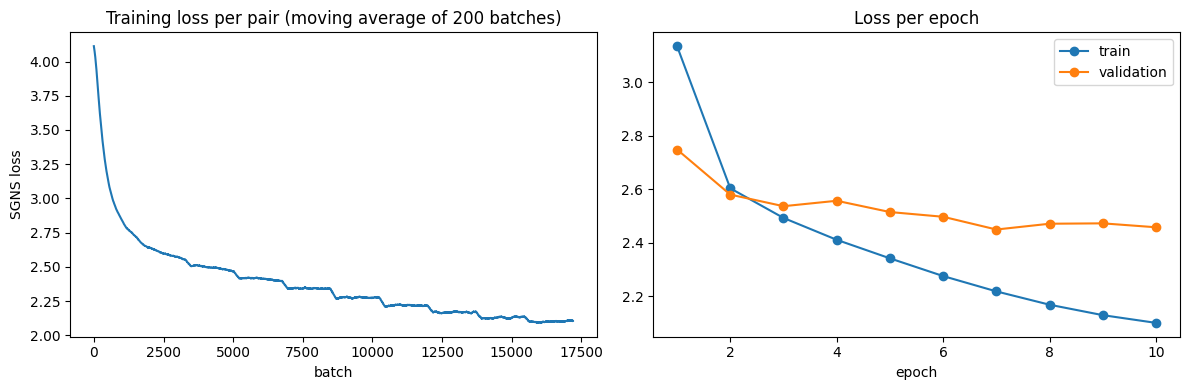

In [22]:
def moving_average(values, width):
    """Smooth a noisy curve by averaging each window of `width` consecutive values."""
    kernel = np.ones(width) / width
    return np.convolve(values, kernel, mode="valid")


figure, (batch_axis, epoch_axis) = plt.subplots(1, 2, figsize=(12, 4))

batch_axis.plot(moving_average(np.array(w2v_history["batch_loss"]), 200))
batch_axis.set_title("Training loss per pair (moving average of 200 batches)")
batch_axis.set_xlabel("batch")
batch_axis.set_ylabel("SGNS loss")

epochs_axis_values = np.arange(1, len(w2v_history["train_loss"]) + 1)
epoch_axis.plot(epochs_axis_values, w2v_history["train_loss"], marker="o", label="train")
epoch_axis.plot(epochs_axis_values, w2v_history["validation_loss"], marker="o", label="validation")
epoch_axis.set_title("Loss per epoch")
epoch_axis.set_xlabel("epoch")
epoch_axis.legend()

plt.tight_layout()
plt.show()

**Observations**

* The gradient check gives a relative error of about $10^{-10}$, so the hand-derived gradients match the numerical ones.
* **Learning rate.** With full 10-epoch runs at $d = 50$, the best validation losses are 2.661 ($\eta$ = 0.01), 2.501 (0.025),
  **2.470 (0.05)** and 2.494 (0.1). A small $\eta$ is still far from a minimum after 10 epochs. $\eta = 0.1$ learns fastest
  but overfits: its training loss keeps falling while the validation loss stops improving. We keep **$\eta = 0.05$**.
* **Embedding size.** With $\eta = 0.05$: 2.470 ($d$ = 50), 2.459 (100), **2.449 (200)**. Larger vectors help a little,
  so we keep **$d = 200$**. The gain from 100 to 200 is small (0.01) for 4× the storage of 50 dimensions, so $d = 100$ would be a reasonable cheaper choice.
* **Epochs.** For the chosen model the validation loss is lowest at **epoch 7** (2.449) and then stays roughly flat
  (2.471, 2.473, 2.458), while the training loss keeps falling (2.22 → 2.10). The extra epochs only fit the training pairs better,
  so the parameters from epoch 7 are kept. The validation curve is a little noisy (for example, epoch 4 is worse than epoch 3) because each epoch
  draws new negatives and a new subsample.

## 1.6 Comparison of the three representations

### Nearest neighbours

In [23]:
QUERY_WORDS = ["stock", "company", "said", "rose", "million", "bank",
               "new", "president", "quarter", "shares", "oil", "computer"]


def similarities_for(method, word_id):
    """Cosine similarities of one word to every word under the given representation."""
    if method == "PPMI":
        return sparse_cosine_similarities(plain_ppmi_matrix, word_id)
    if method == "PPMI a=.75":
        return sparse_cosine_similarities(ppmi_matrix, word_id)
    if method == "TF-IDF":
        return sparse_cosine_similarities(tfidf_matrix, word_id)
    return dense_cosine_similarities(word2vec_embeddings, word_id)


METHODS = ["PPMI", "PPMI a=.75", "TF-IDF", "Word2Vec"]
for word in QUERY_WORDS:
    if word not in vocab:
        print(f"(skipping {word!r}: not in vocabulary)")
        continue
    word_id = vocab.get_id(word)
    print(f"=== {word} ===")
    for method in METHODS:
        neighbours = nearest_neighbours(similarities_for(method, word_id), word_id, vocab, N_NEIGHBOURS)
        print(f"  {method:<11}: {format_neighbours(neighbours)}")

=== stock ===
  PPMI       : exchange (0.23), preferred (0.17), shares (0.14), convertible (0.13), market (0.12), prices (0.11), closed (0.10), trading (0.10)
  PPMI a=.75 : exchange (0.25), preferred (0.18), shares (0.17), market (0.14), convertible (0.13), trading (0.13), mercantile (0.13), closed (0.13)
  TF-IDF     : exchange (0.38), composite (0.36), trading (0.28), york (0.24), closed (0.20), market (0.19), <NUM> (0.17), preferred (0.17)
  Word2Vec   : preferred (0.66), shares (0.64), cboe (0.64), tumble (0.63), guaranteeing (0.63), traded (0.63), split (0.63), 2-for-1 (0.62)
=== company ===
  PPMI       : 's (0.12), beverly (0.12), the (0.11), its (0.10), device (0.10), it (0.10), which (0.09), concern (0.09)
  PPMI a=.75 : beverly (0.13), device (0.12), 's (0.12), republic (0.12), it (0.12), digital (0.11), concern (0.11), its (0.11)
  TF-IDF     : the (0.26), a (0.21), said (0.21), 's (0.19), in (0.18), to (0.17), <NUM> (0.17), of (0.17)
  Word2Vec   : trelleborg (0.55), post 

  PPMI       : equivalents (0.17), common (0.17), outstanding (0.16), million (0.15), stock (0.14), telesis (0.13), stake (0.13), <NUM> (0.12)
  PPMI a=.75 : common (0.20), outstanding (0.19), equivalents (0.18), million (0.18), stock (0.17), <NUM> (0.17), stake (0.15), telesis (0.14)
  TF-IDF     : common (0.28), outstanding (0.28), volume (0.22), <NUM> (0.20), million (0.18), exchange (0.16), buy-back (0.15), stock (0.15)
  Word2Vec   : common (0.76), outstanding (0.73), dilutive (0.72), shrank (0.72), equivalents (0.71), preferred (0.69), soared (0.69), ft-se (0.66)
=== oil ===
  PPMI       : low-sulfur (0.17), fuel (0.15), refining (0.15), prices (0.15), residual (0.14), jet (0.12), crude (0.12), gas (0.12)
  PPMI a=.75 : low-sulfur (0.17), fuel (0.17), refining (0.16), prices (0.16), crude (0.15), gas (0.14), residual (0.14), coal (0.13)
  TF-IDF     : crude (0.36), amoco (0.19), wells (0.18), gas (0.17), symbol (0.15), exploration (0.15), prices (0.14), nationalized (0.14)
  Word

### Sparsity, dimensionality and storage

In [24]:
def describe_sparse(name, matrix):
    n_rows, n_cols = matrix.shape
    density = matrix.nnz() / (n_rows * n_cols)
    dense_bytes = n_rows * n_cols * 4                     # the same matrix stored as dense float32
    return [name, f"{n_rows} x {n_cols}", f"{matrix.nnz():,}", f"{1 - density:.3%}",
            f"{matrix.storage_bytes() / 1e6:.1f} MB", f"{dense_bytes / 1e6:.1f} MB"]


def describe_dense(name, embeddings):
    n_rows, n_cols = embeddings.shape
    as_float32 = embeddings.astype(np.float32)
    n_nonzero = np.count_nonzero(as_float32)
    return [name, f"{n_rows} x {n_cols}", f"{n_nonzero:,}", f"{1 - n_nonzero / as_float32.size:.3%}",
            f"{as_float32.nbytes / 1e6:.1f} MB", f"{as_float32.nbytes / 1e6:.1f} MB"]


table = [
    ["representation", "shape", "non-zeros", "sparsity", "stored size", "dense size"],
    describe_sparse("raw counts", count_matrix),
    describe_sparse("PPMI", plain_ppmi_matrix),
    describe_sparse("PPMI a=.75", ppmi_matrix),
    describe_sparse("TF-IDF", tfidf_matrix),
    describe_dense("Word2Vec", word2vec_embeddings),
]
for row in table:
    print(f"{row[0]:<15}{row[1]:>14}{row[2]:>13}{row[3]:>11}{row[4]:>13}{row[5]:>12}")

representation          shape    non-zeros   sparsity  stored size  dense size
raw counts        7886 x 7886      275,709    99.557%       2.3 MB    248.8 MB
PPMI              7886 x 7886      252,374    99.594%       2.1 MB    248.8 MB
PPMI a=.75        7886 x 7886      254,299    99.591%       2.1 MB    248.8 MB
TF-IDF            7886 x 8043      146,033    99.770%       1.2 MB    253.7 MB
Word2Vec           7886 x 200    1,577,200     0.000%       6.3 MB      6.3 MB


### Discussion

**Semantic quality: what kind of similarity each method finds**

| | Finds | Good examples | Failures |
|---|---|---|---|
| **PPMI** (±2 words) | Words used in the same *position*, plus some words used *next to* them | *rose* → fell, edged, jumped, climbed; *quarter* → fourth, third, year-ago, period | Rare words with one lucky context get high scores (*company* → beverly; *president* → kushkin). Plain PPMI also lets function words through (*company*, *new* → the, a, 's). Smoothing ($\alpha = 0.75$) reduces both a little. |
| **TF-IDF** (sentence = document) | Words that appear in the *same sentences*, i.e. topic | *oil* → crude, wells, gas, exploration; *president* → vice, officer, executive, chief | Frequent words get stop words as neighbours (*company*, *said* → the, a, of), because they share almost every sentence with them; *rose* → `<NUM>`, from, to |
| **Word2Vec** | Words that can *replace* each other (same role in the sentence) | *rose* → jumped, climbed, fell, gained, soared; *president* → vice, executive, chief, officer, chairman; *shares* → common, outstanding, preferred; *quarter* → year-earlier, year-ago, fiscal, period | Less frequent or very general words get noisy neighbours (*computer* → marketer, nabisco, exxon: other company-related nouns; *oil* → crude, then measurements, jeep; *company* → names of companies) |

Cosine values are not comparable *between* methods. Word2Vec scores are high (0.6–0.85) for its top neighbours because all vectors share
the same dense dimensions, while sparse vectors that share few non-zero dimensions have low scores.

**Relevance for POS tagging (Part 3).** An unknown word should borrow the tag behaviour of words that *play the same role*.
Word2Vec and the small-window PPMI find such words (verbs → verbs, nouns → nouns). Even when Word2Vec's neighbours have the wrong topic
(*computer* → *marketer*, *exxon*), they usually have the right part of speech. TF-IDF neighbours often have a different
part of speech (*rose* → `<NUM>`, *from*, *million*), so we expect it to help the HMM the least.

**Sparsity, dimensionality and storage**

* **Dimensionality.** PPMI has one dimension per vocabulary word (7,886) and TF-IDF one per training sentence (8,043). Both grow with the data.
  Word2Vec has a fixed size that we choose: 200, tuned on validation ("short (50–300) and dense", as in lecture 03).
* **Sparsity.** PPMI and TF-IDF are more than 99.5% zeros, and Word2Vec is completely dense. PPMI is slightly sparser than the raw counts,
  because the ~8% of observed pairs with negative PMI are set to 0.
* **Storage.** Stored in CSR, the sparse matrices take only 1–2 MB, less than the 6.3 MB of the 200-dimensional Word2Vec vectors. Stored densely
  they would need ~250 MB each, so a sparse format is essential. Comparing sparse vectors costs time proportional to the number of non-zeros,
  and comparing dense ones costs time proportional to $d$.
* **Interpretability vs generalisation.** Every sparse dimension has a meaning (a context word or a sentence), so similarity can be explained.
  Word2Vec dimensions mean nothing on their own, but the compression forces similar words to share
  parameters, which helps for words with few contexts, where sparse vectors barely overlap.
  This is the "higher-order co-occurrence" advantage from lecture 03: two words that never share a context directly can still get close vectors.

### Hyperparameter summary (Part 1)

| Hyperparameter | Value | How it was chosen |
|---|---|---|
| Word2Vec learning rate $\eta$ | **0.05** | Validation loss, candidates 0.01 / 0.025 / 0.05 / 0.1 (full 10-epoch runs) |
| Word2Vec embedding size $d$ | **200** | Validation loss, candidates 50 / 100 / 200 |
| Word2Vec epochs | **7** (of max 10) | Early stopping: epoch with the lowest validation loss |
| Word2Vec window, $K$ | ±2, 5 | Fixed: they change the validation pairs / loss, so they cannot be compared by validation loss. Revisited in Part 3 |
| PMI window | ±2 | Fixed default; tuned in Part 3 by validation tagging accuracy |
| PPMI smoothing $\alpha$ | 1 (lecture) and 0.75 | Both built and compared; the one used by the HMM is chosen in Part 3 |
| TF-IDF weighting | $1 + \log_{10} f$, $\log_{10} N/\mathrm{df}$ | Lecture formula |
| Vocabulary `MIN_COUNT` | 2 | Fixed default; revisited in Part 3 |
| Subsampling $t$, negative power | $10^{-3}$, 0.75 | Standard word2vec values (0.75 as in lecture 04) |

The test set was not used for any of these choices.